In [7]:
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('data/supermarket.csv')

df

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Date,Time,Payment,Rating
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,1/5/2019,13:08,Ewallet,9.1
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3/8/2019,10:29,Cash,9.6
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,3/3/2019,13:23,Credit card,7.4
3,123-19-1176,A,Yangon,Member,Male,Health and beauty,58.22,8,1/27/2019,20:33,Ewallet,8.4
4,373-73-7910,A,Yangon,Normal,Male,Sports and travel,86.31,7,2/8/2019,10:37,Ewallet,5.3
...,...,...,...,...,...,...,...,...,...,...,...,...
995,233-67-5758,C,Naypyitaw,Normal,Male,Health and beauty,40.35,1,1/29/2019,13:46,Ewallet,6.2
996,303-96-2227,B,Mandalay,Normal,Female,Home and lifestyle,97.38,10,3/2/2019,17:16,Ewallet,4.4
997,727-02-1313,A,Yangon,Member,Male,Food and beverages,31.84,1,2/9/2019,13:22,Cash,7.7
998,347-56-2442,A,Yangon,Normal,Male,Home and lifestyle,65.82,1,2/22/2019,15:33,Cash,4.1


In [8]:
# Menambahkan kolom total penjualan (Unit price * Quantity)
df['Total Sales'] = df['Unit price'] * df['Quantity']

df

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Date,Time,Payment,Rating,Total Sales
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,1/5/2019,13:08,Ewallet,9.1,522.83
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3/8/2019,10:29,Cash,9.6,76.40
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,3/3/2019,13:23,Credit card,7.4,324.31
3,123-19-1176,A,Yangon,Member,Male,Health and beauty,58.22,8,1/27/2019,20:33,Ewallet,8.4,465.76
4,373-73-7910,A,Yangon,Normal,Male,Sports and travel,86.31,7,2/8/2019,10:37,Ewallet,5.3,604.17
...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,233-67-5758,C,Naypyitaw,Normal,Male,Health and beauty,40.35,1,1/29/2019,13:46,Ewallet,6.2,40.35
996,303-96-2227,B,Mandalay,Normal,Female,Home and lifestyle,97.38,10,3/2/2019,17:16,Ewallet,4.4,973.80
997,727-02-1313,A,Yangon,Member,Male,Food and beverages,31.84,1,2/9/2019,13:22,Cash,7.7,31.84
998,347-56-2442,A,Yangon,Normal,Male,Home and lifestyle,65.82,1,2/22/2019,15:33,Cash,4.1,65.82


In [9]:
# Mengonversi kolom 'Date' menjadi format datetime
df['Date'] = pd.to_datetime(df['Date'])

# Mengatur index sebagai 'Date'
df.set_index('Date', inplace=True)

# Menampilkan 5 data pertama untuk memastikan
df.head()

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Time,Payment,Rating,Total Sales
Date,,,,,,,,,,,,
2019-01-05,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,13:08,Ewallet,9.1,522.83
2019-03-08,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,10:29,Cash,9.6,76.40
2019-03-03,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,13:23,Credit card,7.4,324.31
2019-01-27,123-19-1176,A,Yangon,Member,Male,Health and beauty,58.22,8,20:33,Ewallet,8.4,465.76
2019-02-08,373-73-7910,A,Yangon,Normal,Male,Sports and travel,86.31,7,10:37,Ewallet,5.3,604.17


In [11]:
# Mengelompokkan penjualan berdasarkan tanggal
sales_per_day = df.resample('D')['Total Sales'].sum()

sales_per_day

Date
2019-01-01    4519.22
2019-01-02    1852.86
2019-01-03    1979.17
2019-01-04    1546.37
2019-01-05    3368.27
               ...   
2019-03-26    1869.06
2019-03-27    2764.59
2019-03-28    2123.24
2019-03-29    3831.66
2019-03-30    4273.39
Freq: D, Name: Total Sales, Length: 89, dtype: float64

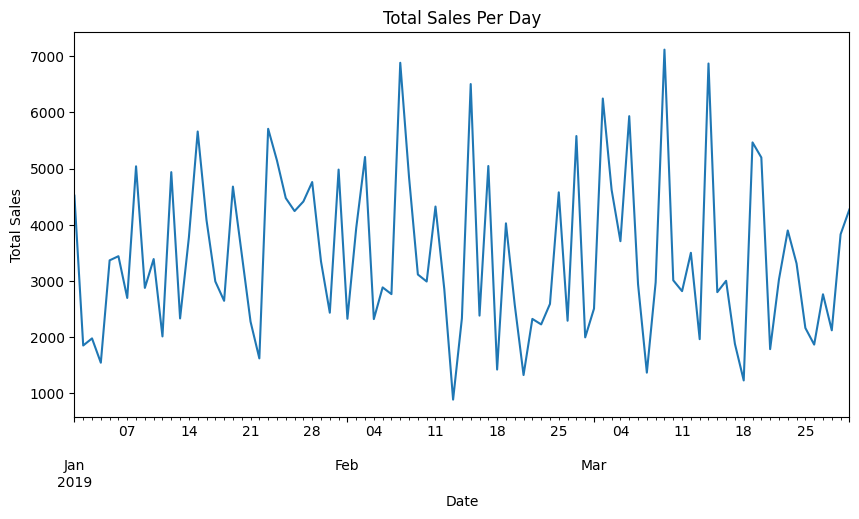

In [12]:
# Plotting penjualan harian

sales_per_day.plot(figsize=(10, 5), title='Total Sales Per Day')
plt.xlabel('Date')
plt.ylabel('Total Sales')
plt.show()

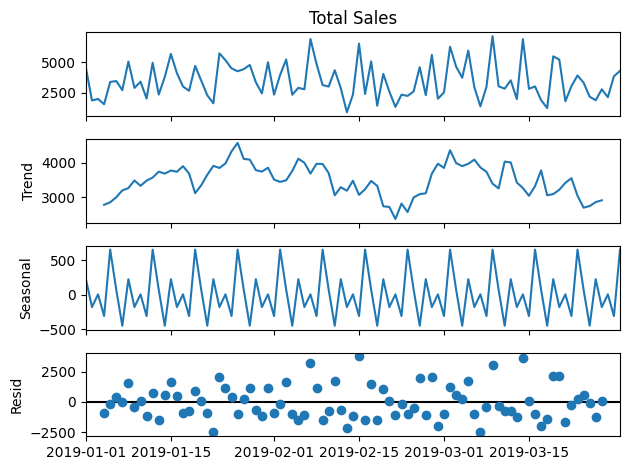

In [24]:
from statsmodels.tsa.seasonal import seasonal_decompose

# Decompose data
decomposition = seasonal_decompose(sales_per_day, model='additive', period=7)

# Plotting hasil decomposition
decomposition.plot()
plt.show()

In [20]:
from statsmodels.tsa.arima.model import ARIMA

# ARIMA model
model = ARIMA(sales_per_day, order=(5, 1, 0))
model_fit = model.fit()

# Prediksi
forecast = model_fit.forecast(steps=10)
print(forecast)

2019-03-31    2571.211019
2019-04-01    2828.824552
2019-04-02    3179.321169
2019-04-03    3404.522319
2019-04-04    3320.169597
2019-04-05    3044.302492
2019-04-06    3076.441935
2019-04-07    3218.484111
2019-04-08    3246.086596
2019-04-09    3188.963827
Freq: D, Name: predicted_mean, dtype: float64


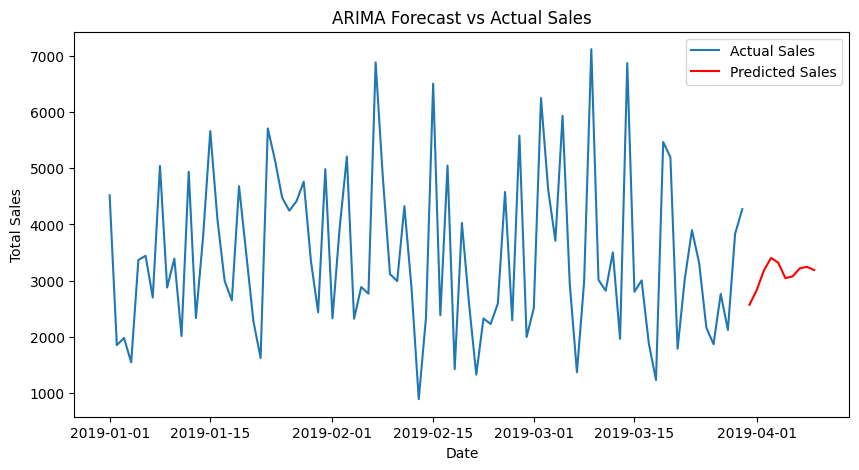

In [21]:
# Plotting prediksi dengan data aktual
plt.figure(figsize=(10, 5))
plt.plot(sales_per_day, label='Actual Sales')
plt.plot(forecast, label='Predicted Sales', color='red')
plt.title('ARIMA Forecast vs Actual Sales')
plt.xlabel('Date')
plt.ylabel('Total Sales')
plt.legend()
plt.show()


In [22]:
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np

# Menghitung MAE, MSE, dan RMSE
mae = mean_absolute_error(sales_per_day[-10:], forecast)
mse = mean_squared_error(sales_per_day[-10:], forecast)
rmse = np.sqrt(mse)

print(f'MAE: {mae}')
print(f'MSE: {mse}')
print(f'RMSE: {rmse}')


MAE: 720.3185328488096
MSE: 671276.581028553
RMSE: 819.3147020703052


In [25]:
df["Total Sales"].mean()

307.58738